In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("server_data.csv")

In [ ]:
df.head()

,ServerType,MemoryUsagePct,DiskIOPct,NetworkLatencyMs,ErrorRate,ApplicationCrashes,MaintenanceCount90d,FailureWithin24h
0,Storage,69.57,58.53,47.42,4,2,1,1
1,Application,49.40,72.98,149.34,4,3,1,1
2,Application,76.26,25.55,97.42,6,3,3,1
3,Storage,79.11,49.29,76.34,6,1,3,1
4,Application,35.73,71.58,89.33,3,0,4,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ServerType           10000 non-null  object 
 1   MemoryUsagePct       10000 non-null  float64
 2   DiskIOPct            10000 non-null  float64
 3   NetworkLatencyMs     10000 non-null  float64
 4   ErrorRate            10000 non-null  int64  
 5   ApplicationCrashes   10000 non-null  int64  
 6   MaintenanceCount90d  10000 non-null  int64  
 7   FailureWithin24h     10000 non-null  int64  
dtypes: float64(3), int64(4), object(1)
memory usage: 625.1+ KB


In [ ]:
df.shape

(10000, 8)

In [ ]:
df.isnull().sum()

,0
ServerType,0
MemoryUsagePct,0
DiskIOPct,0
NetworkLatencyMs,0
ErrorRate,0
ApplicationCrashes,0
MaintenanceCount90d,0
FailureWithin24h,0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MemoryUsagePct,10000.0,64.780392,14.917032,10.00,54.840,64.800,74.7500,99.0
DiskIOPct,10000.0,55.366030,19.758227,5.00,41.750,55.185,68.9100,100.0
NetworkLatencyMs,10000.0,111.456380,53.017653,20.42,74.255,100.825,136.1075,500.0
ErrorRate,10000.0,5.012500,2.264786,0.00,3.000,5.000,6.0000,14.0
ApplicationCrashes,10000.0,0.807900,0.905693,0.00,0.000,1.000,1.0000,6.0
MaintenanceCount90d,10000.0,1.995300,1.422350,0.00,1.000,2.000,3.0000,4.0
FailureWithin24h,10000.0,0.422700,0.494013,0.00,0.000,0.000,1.0000,1.0


In [ ]:
df["FailureWithin24h"].value_counts()

,count
FailureWithin24h,
0,5773
1,4227


In [ ]:
df.groupby("FailureWithin24h")["MemoryUsagePct"].mean()

,MemoryUsagePct
FailureWithin24h,
0,60.761940
1,70.268569


In [ ]:
df.groupby("FailureWithin24h")["DiskIOPct"].mean()

,DiskIOPct
FailureWithin24h,
0,52.280972
1,59.579430


In [ ]:
df.groupby("FailureWithin24h")["NetworkLatencyMs"].mean()

,NetworkLatencyMs
FailureWithin24h,
0,106.07934
1,118.80004


In [ ]:
df.groupby("FailureWithin24h")["ErrorRate"].mean()

,ErrorRate
FailureWithin24h,
0,4.816733
1,5.279868


In [ ]:
df.groupby("FailureWithin24h")["ApplicationCrashes"].mean()

,ApplicationCrashes
FailureWithin24h,
0,0.595358
1,1.098178


In [ ]:
df.groupby("FailureWithin24h")["MemoryUsagePct"].mean()

df.groupby("FailureWithin24h")["DiskIOPct"].mean()

df.groupby("FailureWithin24h")["NetworkLatencyMs"].mean()

df.groupby("FailureWithin24h")["ErrorRate"].mean()

df.groupby("FailureWithin24h")["ApplicationCrashes"].mean()

,ApplicationCrashes
FailureWithin24h,
0,0.595358
1,1.098178


In [ ]:
df.groupby("FailureWithin24h")["MemoryUsagePct"].mean()


,MemoryUsagePct
FailureWithin24h,
0,60.761940
1,70.268569


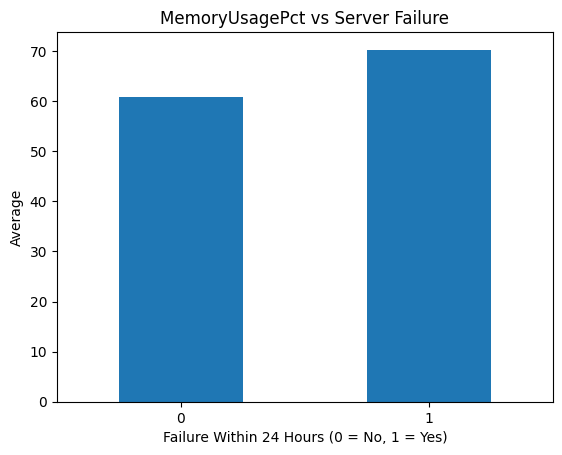

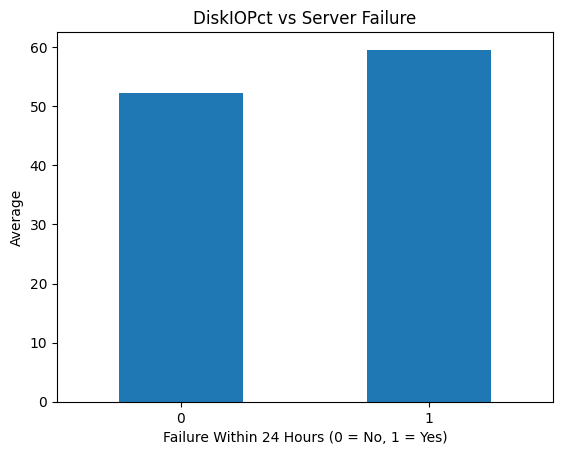

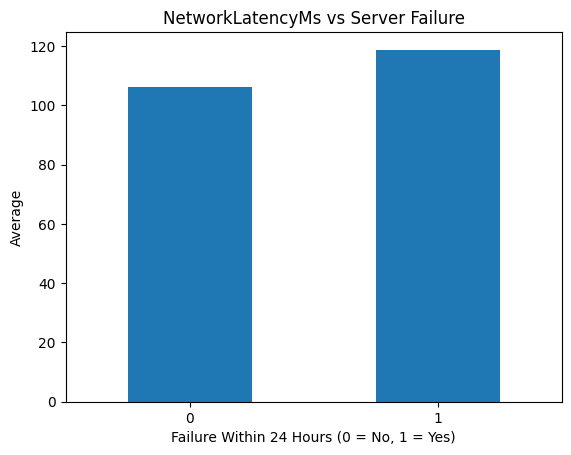

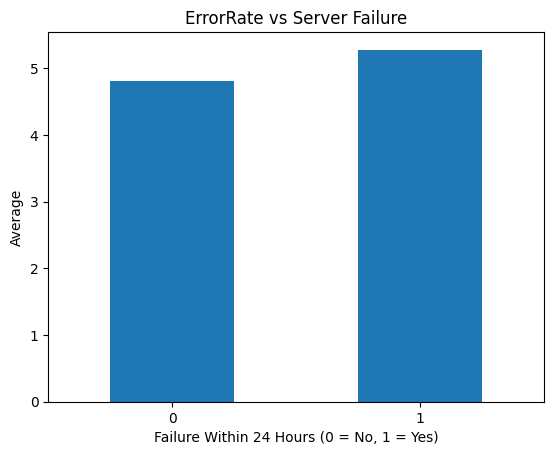

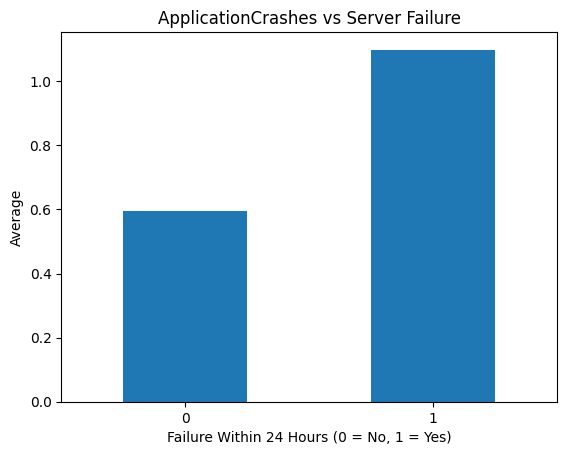

In [ ]:
import matplotlib.pyplot as plt

features = [
    "MemoryUsagePct",
    "DiskIOPct",
    "NetworkLatencyMs",
    "ErrorRate",
    "ApplicationCrashes"
]

for feature in features:
    df.groupby("FailureWithin24h")[feature].mean().plot(kind="bar")

    plt.title(feature + " vs Server Failure")
    plt.xlabel("Failure Within 24 Hours (0 = No, 1 = Yes)")
    plt.ylabel("Average")
    plt.xticks(rotation=0)
    plt.show()

In [ ]:
X = df.drop("FailureWithin24h", axis=1)
y = df["FailureWithin24h"]

In [ ]:
print(X.shape)
print(y.shape)

(10000, 7)
(10000,)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 7)
(2000, 7)
(8000,)
(2000,)


In [ ]:
X = pd.get_dummies(X, columns=["ServerType"], drop_first=True)

In [ ]:
print(X.head())
print(X.shape)

   MemoryUsagePct  DiskIOPct  NetworkLatencyMs  ErrorRate  ApplicationCrashes  \
0           69.57      58.53             47.42          4                   2   
1           49.40      72.98            149.34          4                   3   
2           76.26      25.55             97.42          6                   3   
3           79.11      49.29             76.34          6                   1   
4           35.73      71.58             89.33          3                   0   

   MaintenanceCount90d  ServerType_Database  ServerType_Storage  \
0                    1                False                True   
1                    1                False               False   
2                    3                False               False   
3                    3                False                True   
4                    4                False               False   

   ServerType_Web  
0           False  
1           False  
2           False  
3           False  
4         

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
print(X_train.shape)
print(X_test.shape)

(8000, 9)
(2000, 9)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
print(y_pred[:10])

[0 1 1 1 0 0 0 1 1 1]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7245


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.7094017094017094
Recall: 0.5893491124260355
F1 Score: 0.6438267614738203


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[951 204]
 [347 498]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
rf_pred = rf_model.predict(X_test)

In [ ]:
print(rf_pred[:10])

[0 1 1 0 0 0 1 1 1 1]


In [ ]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7015


In [ ]:
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Precision: 0.6693989071038251
Recall: 0.5798816568047337
F1 Score: 0.62143310082435


In [ ]:
probability = model.predict_proba(X_test_scaled)

print(probability[:5])

[[0.76015729 0.23984271]
 [0.36134702 0.63865298]
 [0.07365777 0.92634223]
 [0.46389717 0.53610283]
 [0.93038031 0.06961969]]


# Demo

In [ ]:
new_server = pd.DataFrame({
    "MemoryUsagePct": [85],
    "DiskIOPct": [80],
    "NetworkLatencyMs": [180],
    "ErrorRate": [8],
    "ApplicationCrashes": [2],
    "MaintenanceCount90d": [1],
    "ServerType_Database": [0],
    "ServerType_Storage": [0],
    "ServerType_Web": [1]
})

In [ ]:
new_server_scaled = scaler.transform(new_server)

prediction = model.predict(new_server_scaled)
probability = model.predict_proba(new_server_scaled)

print("Prediction:", prediction[0])
print("Failure Probability:", probability[0][1])

Prediction: 1
Failure Probability: 0.9588414221792397


In [ ]:
import time

start = time.perf_counter()

prediction = model.predict(new_server_scaled)

end = time.perf_counter()

prediction_time = end - start

print("Prediction:", prediction[0])
print("Prediction Time:", prediction_time, "seconds")

Prediction: 1
Prediction Time: 0.0011357070000030944 seconds


In [ ]:
failure_probability = probability[0][1]

if failure_probability >= 0.70:
    print("⚠️ HIGH RISK: Preventive maintenance recommended.")
else:
    print("✅ LOW RISK: Continue normal monitoring.")

⚠️ HIGH RISK: Preventive maintenance recommended.


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.82      0.78      1155
           1       0.71      0.59      0.64       845

    accuracy                           0.72      2000
   macro avg       0.72      0.71      0.71      2000
weighted avg       0.72      0.72      0.72      2000



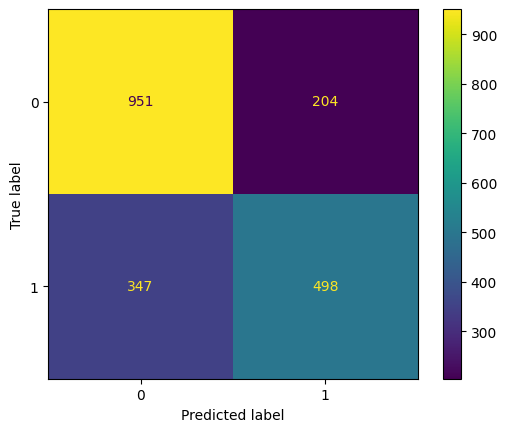

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.show()

In [ ]:
print(X.columns)

Index(['MemoryUsagePct', 'DiskIOPct', 'NetworkLatencyMs', 'ErrorRate',
       'ApplicationCrashes', 'MaintenanceCount90d', 'ServerType_Database',
       'ServerType_Storage', 'ServerType_Web'],
      dtype='object')
